# Лабораторная работа №17: Diffusion model с нуля и classifier-free guidance

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать forward noising и noise prediction.
- Обучить compact conditional network.
- Добавить CFG и сравнить guidance scales.

## Теоретическая часть

DDPM постепенно добавляет Gaussian noise, затем обучает network обращать процесс. Classifier-free guidance смешивает conditional и unconditional predictions и управляет компромиссом fidelity/diversity.

![DDPM](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/ddpm.png)


DDPM обучает εθ(x_t,t,y) восстанавливать внесённый шум. При classifier-free dropout условие заменяется специальным индексом 10; на inference ε_cfg=ε_u+w(ε_c−ε_u). Для MNIST качество класса проверяет отдельно обученный на train классификатор, его точность на test обязательно сообщается.

Прямой процесс: $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$. CFG: $\hat\epsilon=\epsilon_u+w(\epsilon_c-\epsilon_u)$; при двух вызовах сети на шаг $\mathrm{NFE}=2T$.

### Экспериментальный протокол

Данные MNIST: train первые 20 000, test первые 2 000, без пересечения. Полное обучение: 10 000 шагов; smoke: 2. Основной результат — реальные MNIST checkpoint и условная генерация при разных w. Для продолжения после сбоя сохраняйте artifacts в Drive или задайте CV_ARTIFACTS. Не смешивайте smoke/full checkpoint.

### Материалы

- [DDPM paper](https://arxiv.org/abs/2006.11239)
- [Annotated Diffusion](https://huggingface.co/blog/annotated-diffusion)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
# локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', str(Path.cwd().parents[1] / 'data')))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'mps', 'fast_dev_run': False, 'artifacts': 'artifacts'}


### Расписание прямой диффузии

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума.

**Результат.** Проверяемое состояние «Расписание прямой диффузии» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума» и его результат доступен следующему этапу.

In [2]:
import math
import torch.nn as nn
import torch.nn.functional as F

T = 1000
def diffusion_schedule(T, kind="linear"):
    if kind == "linear":
        betas = torch.linspace(1e-4, 0.02, T, dtype=torch.float64)
    else:   # cosine (Nichol & Dhariwal), используется в бонусе
        s = 0.008
        f = torch.cos(((torch.arange(T + 1, dtype=torch.float64) / T) + s) / (1 + s) * math.pi / 2) ** 2
        betas = (1 - f[1:] / f[:-1]).clamp(max=0.999)
    alphas = 1 - betas
    alpha_bar = torch.cumprod(alphas, 0)
    return {"betas": betas.float(), "alphas": alphas.float(), "alpha_bar": alpha_bar.float(), "kind": kind, "T": T}

sched = diffusion_schedule(T)

def q_sample(x0, t, noise, s=sched):
    """x_t = sqrt(ᾱ_t)·x0 + sqrt(1−ᾱ_t)·ε — шум передаётся снаружи."""
    ab = s["alpha_bar"].to(x0.device)[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

ab = sched["alpha_bar"]
assert torch.allclose(ab, torch.cumprod(1 - sched["betas"], 0)) and (ab[1:] < ab[:-1]).all()
x0_chk = torch.full((20000, 1, 1, 1), 0.7)
eps_chk = torch.randn(20000, 1, 1, 1, generator=torch.Generator().manual_seed(SEED))
t_chk = torch.full((20000,), 500)
xt = q_sample(x0_chk, t_chk, eps_chk)
emp_mean, emp_std = xt.mean().item(), xt.std().item()
print(f"ᾱ_0={ab[0]:.5f}, ᾱ_499={ab[499]:.4f}, ᾱ_999={ab[-1]:.2e}")
print(f"t=500: эмпирическое среднее {emp_mean:.4f} (теория {0.7 * ab[500].sqrt():.4f}), std {emp_std:.4f} (теория {(1 - ab[500]).sqrt():.4f})")
assert abs(emp_mean - 0.7 * ab[500].sqrt().item()) < 0.02 and abs(emp_std - (1 - ab[500]).sqrt().item()) < 0.02

ᾱ_0=0.99990, ᾱ_499=0.0786, ᾱ_999=4.04e-05
t=500: эмпирическое среднее 0.2040 (теория 0.1952), std 0.9622 (теория 0.9603)


### Условный denoiser и проверка форм

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода.

**Результат.** Проверяемое состояние «Условный denoiser и проверка форм» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода» и его результат доступен следующему этапу.

In [3]:
NULL_CLASS = 10

class TimeClassEmbedding(nn.Module):
    def __init__(self, dim=256):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.cls = nn.Embedding(11, dim)        # 10 цифр + «пустой» класс для classifier-free guidance
    def forward(self, t, y):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        ang = t.float()[:, None] * freqs[None]
        return self.mlp(torch.cat([ang.sin(), ang.cos()], 1)) + self.cls(y)

class ResBlock(nn.Module):
    def __init__(self, cin, cout, emb_dim=256):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x))) + self.emb(e)[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)

class TinyDenoiser(nn.Module):
    """Компактный U-Net 28→14→7 с embedding времени и класса; предсказывает ε."""
    def __init__(self, ch=(64, 128, 128)):
        super().__init__()
        self.emb = TimeClassEmbedding()
        self.inp = nn.Conv2d(1, ch[0], 3, padding=1)
        self.d1, self.d2, self.d3 = ResBlock(ch[0], ch[0]), ResBlock(ch[0], ch[1]), ResBlock(ch[1], ch[2])
        self.down1, self.down2 = nn.Conv2d(ch[0], ch[0], 4, 2, 1), nn.Conv2d(ch[1], ch[1], 4, 2, 1)
        self.mid = ResBlock(ch[2], ch[2])
        self.up2, self.up1 = nn.ConvTranspose2d(ch[2], ch[1], 4, 2, 1), nn.ConvTranspose2d(ch[1], ch[0], 4, 2, 1)
        self.u2, self.u1 = ResBlock(2 * ch[1], ch[1]), ResBlock(2 * ch[0], ch[0])
        self.out = nn.Sequential(nn.GroupNorm(8, ch[0]), nn.SiLU(), nn.Conv2d(ch[0], 1, 3, padding=1))
    def forward(self, x, t, y):
        e = self.emb(t, y)
        h1 = self.d1(self.inp(x), e)                  # 28×28
        h2 = self.d2(self.down1(h1), e)               # 14×14
        h3 = self.mid(self.d3(self.down2(h2), e), e)  # 7×7
        u2 = self.u2(torch.cat([self.up2(h3), h2], 1), e)
        u1 = self.u1(torch.cat([self.up1(u2), h1], 1), e)
        return self.out(u1)

model = TinyDenoiser().to(DEVICE)
with torch.no_grad():
    out = model(torch.randn(4, 1, 28, 28, device=DEVICE), torch.randint(0, T, (4,), device=DEVICE), torch.tensor([0, 3, 9, NULL_CLASS], device=DEVICE))
assert out.shape == (4, 1, 28, 28)
print("TinyDenoiser:", sum(p.numel() for p in model.parameters()) / 1e6, "M параметров; выход", tuple(out.shape))

TinyDenoiser: 2.512769 M параметров; выход (4, 1, 28, 28)


### Train/test MNIST для DDPM

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите фиксированный непересекающийся split и DataLoader.

**Результат.** Проверяемое состояние «Train/test MNIST для DDPM» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите фиксированный непересекающийся split и DataLoader» и его результат доступен следующему этапу.

In [4]:
import torchvision
from torch.utils.data import DataLoader, TensorDataset
mnist_train = torchvision.datasets.MNIST(DATA_ROOT, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(DATA_ROOT, train=False, download=True)
N_TRAIN, N_TEST = 20000, 2000
# фиксированный split по протоколу: первые 20 000 official train и первые 2 000 official test
X_train = mnist_train.data[:N_TRAIN].float().div(127.5).sub(1).unsqueeze(1); y_train = mnist_train.targets[:N_TRAIN]
X_test = mnist_test.data[:N_TEST].float().div(127.5).sub(1).unsqueeze(1); y_test = mnist_test.targets[:N_TEST]
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True, drop_last=True,
                          generator=torch.Generator().manual_seed(SEED))
assert X_train.min() >= -1 and X_train.max() <= 1
print("train", tuple(X_train.shape), "test", tuple(X_test.shape), "классы train:", torch.bincount(y_train).tolist())

train (20000, 1, 28, 28) test (2000, 1, 28, 28) классы train: [1994, 2281, 1929, 2076, 1945, 1775, 1971, 2093, 1922, 2014]


### Обучение epsilon-предсказателя с CFG dropout

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора.

**Результат.** Проверяемое состояние «Обучение epsilon-предсказателя с CFG dropout» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора» и его результат доступен следующему этапу.

In [5]:
import copy
STEPS = 2 if FAST_DEV_RUN else 10000
P_UNCOND, LR, EMA_DECAY = 0.1, 2e-4, 0.999
ckpt_path = ARTIFACTS / ("ddpm_smoke.pt" if FAST_DEV_RUN else "ddpm.pt")   # smoke и full чекпоинты не смешиваются

def train_ddpm(model, s, steps, path, seed=SEED):
    ema = copy.deepcopy(model).eval()
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
    state = {"step": 0, "loss": []}
    if path.exists():
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"]); opt.load_state_dict(ck["optimizer"]); state = ck["state"]
        print(f"продолжаю с шага {state['step']}")
    g = torch.Generator().manual_seed(seed + state["step"])
    base_seconds = state.get("seconds", 0.0)
    ab = s["alpha_bar"].to(DEVICE)
    t0 = time.time()
    while state["step"] < steps:
        for x0, y in train_loader:
            x0, y = x0.to(DEVICE), y.to(DEVICE)
            t = torch.randint(0, s["T"], (len(x0),), generator=g).to(DEVICE)
            noise = torch.randn(x0.shape, generator=g).to(DEVICE)
            drop = torch.rand(len(y), generator=g).to(DEVICE) < P_UNCOND
            y_in = torch.where(drop, torch.full_like(y, NULL_CLASS), y)       # classifier-free dropout
            loss = F.mse_loss(model(q_sample(x0, t, noise, s), t, y_in), noise)
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.lerp_(pm, 1 - EMA_DECAY)
            state["step"] += 1; state["loss"].append(loss.item())
            if state["step"] % 1000 == 0 or state["step"] == steps:
                state["seconds"] = base_seconds + time.time() - t0
                torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "optimizer": opt.state_dict(), "state": state,
                            "schedule": s["kind"], "T": s["T"], "null_class": NULL_CLASS, "p_uncond": P_UNCOND}, path)
                print(f"шаг {state['step']}/{steps}: loss (последние 200) {np.mean(state['loss'][-200:]):.4f}, {time.time() - t0:.0f} c")
            if state["step"] >= steps:
                break
    return ema, state

torch.manual_seed(SEED)
model = TinyDenoiser().to(DEVICE)
ema_model, train_state = train_ddpm(model, sched, STEPS, ckpt_path)
ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
assert ck["state"]["step"] == STEPS and "optimizer" in ck and "ema" in ck
print(f"сохранено: {ckpt_path.name}, шагов {ck['state']['step']}, финальный loss {np.mean(train_state['loss'][-200:]):.4f}")

шаг 1000/10000: loss (последние 200) 0.0285, 92 c


шаг 2000/10000: loss (последние 200) 0.0251, 184 c


шаг 3000/10000: loss (последние 200) 0.0235, 276 c


шаг 4000/10000: loss (последние 200) 0.0231, 368 c


шаг 5000/10000: loss (последние 200) 0.0226, 460 c


шаг 6000/10000: loss (последние 200) 0.0227, 546 c


шаг 7000/10000: loss (последние 200) 0.0218, 618 c


шаг 8000/10000: loss (последние 200) 0.0217, 689 c


шаг 9000/10000: loss (последние 200) 0.0220, 762 c


шаг 10000/10000: loss (последние 200) 0.0218, 835 c
сохранено: ddpm.pt, шагов 10000, финальный loss 0.0218


### Независимый классификатор для оценки

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите только на train и измерьте точность классификатора на real test.

**Результат.** Проверяемое состояние «Независимый классификатор для оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите только на train и измерьте точность классификатора на real test» и его результат доступен следующему этапу.

In [6]:
class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
                               nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 10))
    def forward(self, x):            # x в [-1, 1]
        return self.f(x)

torch.manual_seed(SEED)
clf = DigitClassifier().to(DEVICE)
copt = torch.optim.Adam(clf.parameters(), lr=1e-3)
CLF_EPOCHS = 1 if FAST_DEV_RUN else 4
for epoch in range(CLF_EPOCHS):
    clf.train()
    for x, y in DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(SEED + epoch)):
        loss = F.cross_entropy(clf(x.to(DEVICE)), y.to(DEVICE))
        copt.zero_grad(); loss.backward(); copt.step()
clf.eval()
with torch.no_grad():
    test_pred = torch.cat([clf(X_test[i:i + 500].to(DEVICE)).argmax(1).cpu() for i in range(0, N_TEST, 500)])
clf_acc = float((test_pred == y_test).float().mean())
torch.save({"state_dict": clf.state_dict(), "train_split": "MNIST train[:20000]"}, ARTIFACTS / "classifier.pt")
save_json("classifier_validation.json", {"test_accuracy": clf_acc, "n_test": N_TEST, "split": "MNIST test[:2000]", "epochs": CLF_EPOCHS})
print(f"классификатор: accuracy на реальном test = {clf_acc:.4f}")

классификатор: accuracy на реальном test = 0.9750


### Сбалансированные классы и общий шум

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG.

**Результат.** Проверяемое состояние «Сбалансированные классы и общий шум» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG» и его результат доступен следующему этапу.

In [7]:
PER_CLASS = 2 if FAST_DEV_RUN else 20
y_gen = torch.arange(10).repeat_interleave(PER_CLASS)
NOISE_SEED = SEED + 17
x_T = torch.randn(len(y_gen), 1, 28, 28, generator=torch.Generator().manual_seed(NOISE_SEED))
print("классы:", torch.bincount(y_gen).tolist(), "| общий начальный шум", tuple(x_T.shape), "seed", NOISE_SEED)

классы: [20, 20, 20, 20, 20, 20, 20, 20, 20, 20] | общий начальный шум (200, 1, 28, 28) seed 59


### DDPM sampling и guidance

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE.

**Результат.** Проверяемое состояние «DDPM sampling и guidance» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE» и его результат доступен следующему этапу.

{0.0: {'seconds': 26.81, 'nfe_total': 1000, 'nfe_per_image_step': 1.0}, 1.0: {'seconds': 26.97, 'nfe_total': 1000, 'nfe_per_image_step': 1.0}, 2.0: {'seconds': 52.43, 'nfe_total': 2000, 'nfe_per_image_step': 2.0}, 3.0: {'seconds': 52.17, 'nfe_total': 2000, 'nfe_per_image_step': 2.0}, 5.0: {'seconds': 52.33, 'nfe_total': 2000, 'nfe_per_image_step': 2.0}}


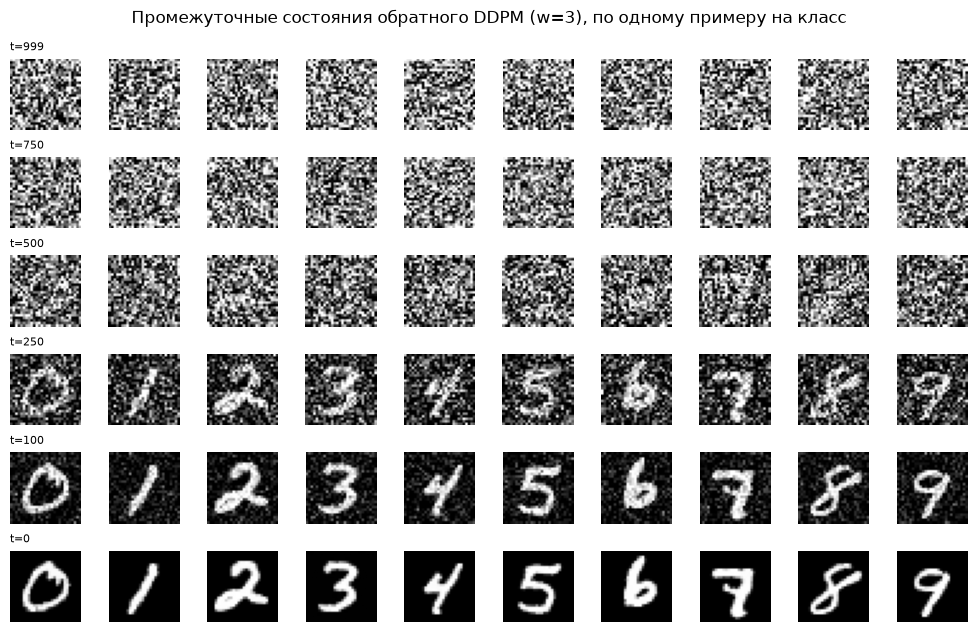

In [8]:
@torch.no_grad()
def guided_eps(net, x, t, y, w):
    """ε_cfg = ε_u + w(ε_c − ε_u); возвращает также число вызовов сети на этом шаге."""
    if w == 0:
        return net(x, t, torch.full_like(y, NULL_CLASS)), 1
    if w == 1:
        return net(x, t, y), 1
    eps = net(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, torch.full_like(y, NULL_CLASS)]))
    e_c, e_u = eps.chunk(2)
    return e_u + w * (e_c - e_u), 2

@torch.no_grad()
def ddpm_sample(net, x_T, y, w, s=sched, noise_seed=NOISE_SEED, keep=()):
    betas, alphas, ab = (s[k].to(DEVICE) for k in ("betas", "alphas", "alpha_bar"))
    g = torch.Generator().manual_seed(noise_seed)      # одинаковые шумы шагов для всех w
    x, y = x_T.to(DEVICE), y.to(DEVICE)
    nfe, frames = 0, {}
    for i in reversed(range(s["T"])):
        t = torch.full((len(x),), i, device=DEVICE, dtype=torch.long)
        eps, n = guided_eps(net, x, t, y, w); nfe += n
        mean = (x - betas[i] / (1 - ab[i]).sqrt() * eps) / alphas[i].sqrt()
        if i > 0:
            var = betas[i] * (1 - ab[i - 1]) / (1 - ab[i])          # апостериорная дисперсия β̃_t
            x = mean + var.sqrt() * torch.randn(x.shape, generator=g).to(DEVICE)
        else:
            x = mean
        if i in keep:
            frames[i] = x.clamp(-1, 1).cpu()
    return x.clamp(-1, 1).cpu(), nfe, frames

GUIDANCE = [0.0, 1.0, 2.0, 3.0, 5.0]
generated, timing = {}, {}
for w in GUIDANCE:
    t0 = time.time()
    imgs, nfe, frames = ddpm_sample(ema_model, x_T, y_gen, w, keep=(999, 750, 500, 250, 100, 0) if w == 3.0 else ())
    timing[w] = {"seconds": time.time() - t0, "nfe_total": nfe, "nfe_per_image_step": nfe / T}
    generated[w] = imgs
    if w == 3.0:
        traj = frames
print({w: {k: round(v, 2) for k, v in d.items()} for w, d in timing.items()})

import matplotlib.pyplot as plt
fig, axes = plt.subplots(6, 10, figsize=(10, 6.4))
for r, step in enumerate(sorted(traj, reverse=True)):
    for c in range(10):
        axes[r, c].imshow(traj[step][c * PER_CLASS, 0], cmap="gray", vmin=-1, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(f"t={step}", fontsize=8, loc="left")
fig.suptitle("Промежуточные состояния обратного DDPM (w=3), по одному примеру на класс"); fig.tight_layout()
fig.savefig(ARTIFACTS / "ddpm_trajectory.png", dpi=110); plt.show()

### Сохранение измерений генерации

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните метрики, изображения и точность проверяющего классификатора на test.

**Результат.** Проверяемое состояние «Сохранение измерений генерации» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните метрики, изображения и точность проверяющего классификатора на test» и его результат доступен следующему этапу.

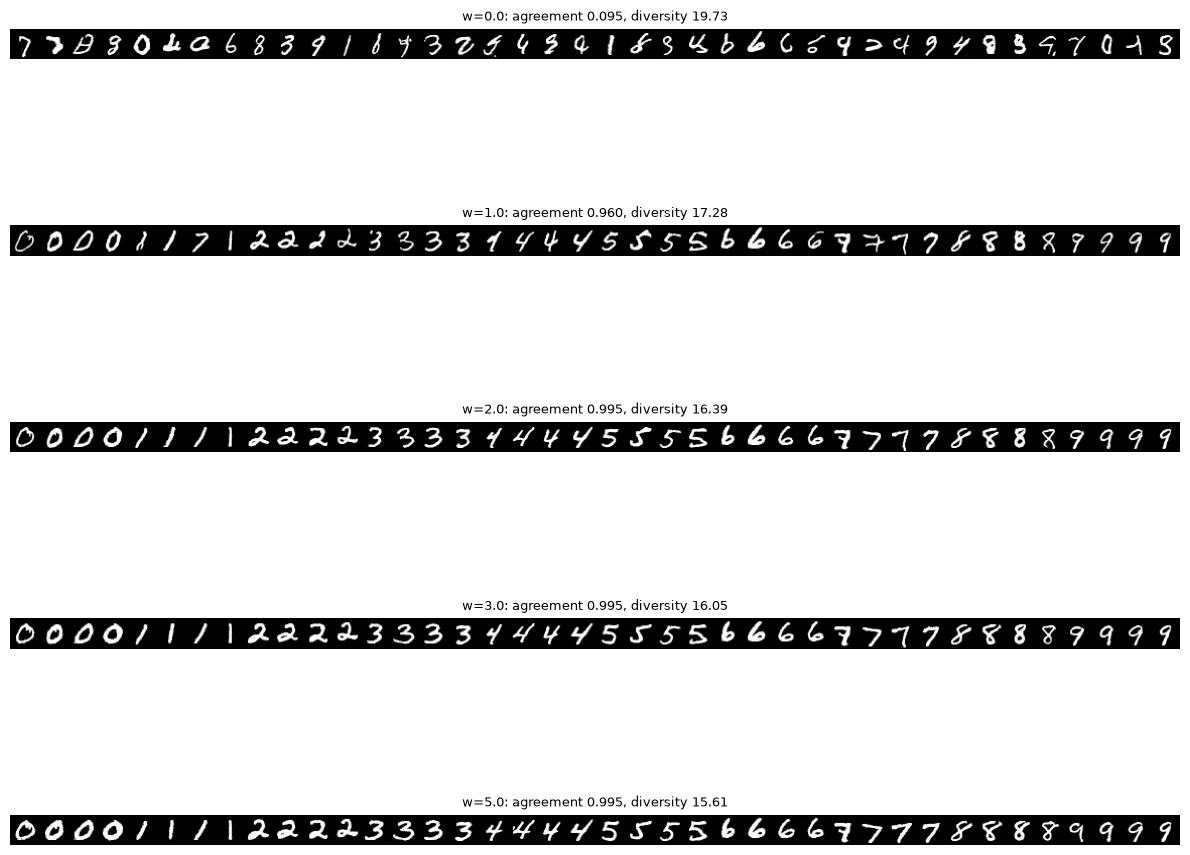

     class_agreement  mean_confidence  intra_class_l2_diversity  seconds  nfe_total  nfe_per_image_step
0.0            0.095           0.8558                   19.7310  26.8150     1000.0                 1.0
1.0            0.960           0.9739                   17.2834  26.9686     1000.0                 1.0
2.0            0.995           0.9981                   16.3898  52.4263     2000.0                 2.0
3.0            0.995           0.9980                   16.0506  52.1654     2000.0                 2.0
5.0            0.995           0.9978                   15.6109  52.3265     2000.0                 2.0
реальные test-изображения (эталон проверяющего): {'class_agreement': 0.995, 'mean_confidence': 0.9817, 'intra_class_l2_diversity': 17.406}


In [9]:
@torch.no_grad()
def evaluate_images(imgs, y):
    logits = torch.cat([clf(imgs[i:i + 500].to(DEVICE)).cpu() for i in range(0, len(imgs), 500)])
    prob = logits.softmax(1)
    agree = float((logits.argmax(1) == y).float().mean())
    div = []
    for c in range(10):
        f = imgs[y == c].flatten(1)
        d = torch.cdist(f, f)
        div.append(float(d[~torch.eye(len(f), dtype=bool)].mean()))
    return {"class_agreement": agree, "mean_confidence": float(prob.max(1).values.mean()),
            "intra_class_l2_diversity": float(np.mean(div)), "per_class_agreement": [float((logits.argmax(1)[y == c] == c).float().mean()) for c in range(10)]}

gen_metrics = {}
for w in GUIDANCE:
    gen_metrics[str(w)] = {**evaluate_images(generated[w], y_gen), **timing[w]}
real_ref = evaluate_images(X_test[:len(y_gen)], y_test[:len(y_gen)])
save_json("generation_metrics.json", {"classifier_test_accuracy": clf_acc, "per_class_images": PER_CLASS, "T": T,
                                       "guidance": gen_metrics, "real_test_reference": real_ref})
fig, axes = plt.subplots(len(GUIDANCE), 1, figsize=(12, 2.2 * len(GUIDANCE)))
for ax, w in zip(axes, GUIDANCE):
    grid = torchvision.utils.make_grid(generated[w][::max(1, PER_CLASS // 4)][:40].add(1).div(2), nrow=40, padding=1)
    ax.imshow(grid.permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"w={w}: agreement {gen_metrics[str(w)]['class_agreement']:.3f}, diversity {gen_metrics[str(w)]['intra_class_l2_diversity']:.2f}", fontsize=9)
fig.tight_layout(); fig.savefig(ARTIFACTS / "guidance_grid.png", dpi=110); plt.show()
import pandas as pd
print(pd.DataFrame({w: {k: v for k, v in m.items() if k != "per_class_agreement"} for w, m in gen_metrics.items()}).T.round(4).to_string())
print("реальные test-изображения (эталон проверяющего):", {k: round(v, 4) for k, v in real_ref.items() if k != "per_class_agreement"})

### Шумовая ошибка на разных временах

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps.

**Результат.** Проверяемое состояние «Шумовая ошибка на разных временах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps» и его результат доступен следующему этапу.

In [10]:
EVAL_T = [10, 100, 250, 500, 750, 900, 999]
xb, yb = X_test[:256].to(DEVICE), y_test[:256].to(DEVICE)
g = torch.Generator().manual_seed(SEED + 99)
noise_b = torch.randn(xb.shape, generator=g).to(DEVICE)
mse_t = {}
with torch.no_grad():
    for tt in EVAL_T:
        t = torch.full((len(xb),), tt, device=DEVICE)
        xt = q_sample(xb, t, noise_b)
        e_c = ema_model(xt, t, yb); e_u = ema_model(xt, t, torch.full_like(yb, NULL_CLASS))
        mse_t[tt] = {"conditional": float(F.mse_loss(e_c, noise_b)), "unconditional": float(F.mse_loss(e_u, noise_b))}
save_json("noise_mse_by_t.json", {"n_test_images": len(xb), "mse": mse_t})
print(pd.DataFrame(mse_t).T.round(5).to_string())

     conditional  unconditional
10       0.12280        0.12297
100      0.05434        0.05452
250      0.02902        0.02983
500      0.01079        0.01323
750      0.00070        0.00085
900      0.00009        0.00011
999      0.00006        0.00006


### Худшие ошибки denoiser

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте реальные ошибки и пять худших test изображений.

**Результат.** Проверяемое состояние «Худшие ошибки denoiser» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте реальные ошибки и пять худших test изображений» и его результат доступен следующему этапу.

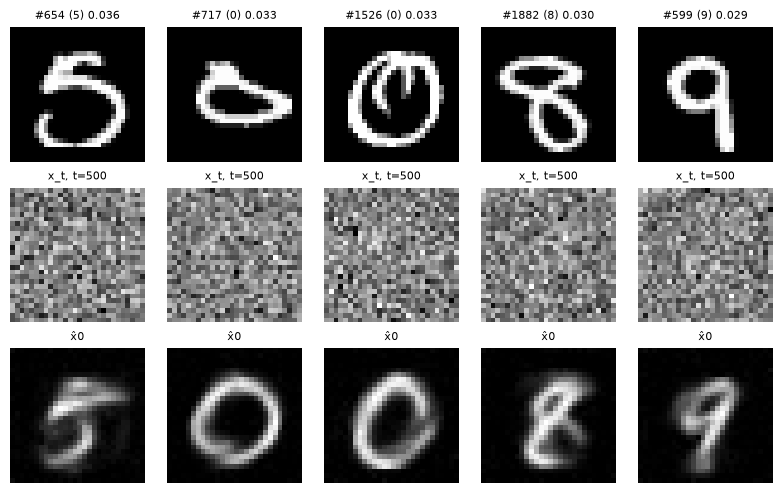

5 худших test-изображений по ошибке шума: [(654, 5, 0.0359), (717, 0, 0.0333), (1526, 0, 0.0332), (1882, 8, 0.0296), (599, 9, 0.0292)]


In [11]:
T_WORST = 500
with torch.no_grad():
    t = torch.full((N_TEST,), T_WORST, device=DEVICE)
    noise_all = torch.randn(X_test.shape, generator=torch.Generator().manual_seed(SEED + 5)).to(DEVICE)
    xt_all = q_sample(X_test.to(DEVICE), t, noise_all)
    per_img = torch.cat([F.mse_loss(ema_model(xt_all[i:i + 500], t[i:i + 500], y_test[i:i + 500].to(DEVICE)), noise_all[i:i + 500], reduction="none").mean((1, 2, 3)).cpu()
                         for i in range(0, N_TEST, 500)])
worst = torch.argsort(per_img, descending=True)[:5]
save_json("worst_denoising.json", {"t": T_WORST, "mean_mse": float(per_img.mean()), "worst": [
    {"test_index": int(i), "label": int(y_test[i]), "mse": float(per_img[i])} for i in worst]})
ab_w = sched["alpha_bar"][T_WORST]
x0_hat = ((xt_all[worst] - (1 - ab_w).sqrt() * ema_model(xt_all[worst], t[:5], y_test[worst].to(DEVICE))) / ab_w.sqrt()).clamp(-1, 1).detach().cpu()
fig, axes = plt.subplots(3, 5, figsize=(8, 5))
for k, i in enumerate(worst):
    axes[0, k].imshow(X_test[i, 0], cmap="gray"); axes[0, k].set_title(f"#{int(i)} ({int(y_test[i])}) {per_img[i]:.3f}", fontsize=8)
    axes[1, k].imshow(xt_all[i, 0].cpu(), cmap="gray"); axes[1, k].set_title(f"x_t, t={T_WORST}", fontsize=8)
    axes[2, k].imshow(x0_hat[k, 0], cmap="gray"); axes[2, k].set_title("x̂0", fontsize=8)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "worst_denoising.png", dpi=110); plt.show()
print("5 худших test-изображений по ошибке шума:", [(int(i), int(y_test[i]), round(float(per_img[i]), 4)) for i in worst])

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

In [12]:
# Гипотеза (до просмотра результатов): косинусное расписание шума при том же бюджете (10 000 шагов, тот же seed,
# те же данные, архитектура и w=3) даст не худшее согласование классов и большее разнообразие, потому что
# линейное расписание тратит много шагов на почти чистый шум в конце траектории.
sched_cos = diffusion_schedule(T, "cosine")
torch.manual_seed(SEED)
model_cos = TinyDenoiser().to(DEVICE)
ema_cos, state_cos = train_ddpm(model_cos, sched_cos, STEPS, ARTIFACTS / ("ddpm_cosine_smoke.pt" if FAST_DEV_RUN else "ddpm_cosine.pt"))
bonus = {}
for name, net, s in [("linear", ema_model, sched), ("cosine", ema_cos, sched_cos)]:
    imgs, nfe, _ = ddpm_sample(net, x_T, y_gen, 3.0, s=s)
    bonus[name] = {**{k: v for k, v in evaluate_images(imgs, y_gen).items() if k != "per_class_agreement"},
                   "final_train_loss": float(np.mean((train_state if name == "linear" else state_cos)["loss"][-500:])),
                   "alpha_bar_at_T/2": float(s["alpha_bar"][T // 2])}
save_json("bonus_schedule.json", bonus)
print(pd.DataFrame(bonus).T.round(4).to_string())

шаг 1000/10000: loss (последние 200) 0.0471, 74 c


шаг 2000/10000: loss (последние 200) 0.0425, 166 c


шаг 3000/10000: loss (последние 200) 0.0406, 259 c


шаг 4000/10000: loss (последние 200) 0.0400, 351 c


шаг 5000/10000: loss (последние 200) 0.0389, 427 c


шаг 6000/10000: loss (последние 200) 0.0388, 500 c


шаг 7000/10000: loss (последние 200) 0.0379, 574 c


шаг 8000/10000: loss (последние 200) 0.0378, 648 c


шаг 9000/10000: loss (последние 200) 0.0380, 723 c


шаг 10000/10000: loss (последние 200) 0.0376, 795 c


        class_agreement  mean_confidence  intra_class_l2_diversity  final_train_loss  alpha_bar_at_T/2
linear            0.995           0.9980                   16.0506            0.0217            0.0778
cosine            1.000           0.9995                   16.3923            0.0375            0.4923


## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.